[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/multigeom/multigeom-tutorials/blob/steeve-g/notebooks/10_coding_spectrum.ipynb)

# Coding spectrum

* **Author**: laquitainesteeve@gmail.com

* **Goal**: Plot the coding spectrum $\rho(\tau)$ of V1 and V4 against $\tau = \log t$ under the envelope spectrum of notebook 9, from stimulus–response pairs, and report $\tfrac12 \int \rho\, d\tau = I(R; X)$ for each area (task 4 of the note *Scale-resolved decomposition of G(x)*).

* **Requirements**: TinyImageNet and the trained checkpoints (downloaded below), a GPU, and a version of `multigeom` that has `compute_coding_spectrum` (newer than 0.1.0.dev4: until it is released, install the package from a clone, see the README).

* **Time**: about 7 min on a GPU.

## 1. Setup

### 1.1. Install package

Install the version of `multigeom` this notebook needs, the `g-per-scale` branch on GitHub: on Google Colab always (with `diffusers`), elsewhere only if the installed one lacks its functions.

time: <1 sec

In [1]:
%%time

# the multigeom this notebook needs: the g-per-scale branch on GitHub, until it is
# released (without its dependencies: Colab already has torch, numpy, scipy and
# matplotlib, and reinstalling torch is slow and can break the GPU runtime)
import os
import sys

BRANCH = "git+https://github.com/multigeom/multigeom.git@g-per-scale"

# on Google Colab: install the latest commit of that branch (forced: pip skips a
# branch it installed before, even if the branch has changed since), and the
# diffusion models' library
if "google.colab" in sys.modules:
    %pip install -q --no-deps --force-reinstall {BRANCH}
    %pip install -q "diffusers>=0.30,<0.38"

    # an older multigeom imported earlier in this session stays in memory: restart
    # the session so that the next cells import the new one (then run them from the
    # next cell on)
    if "multigeom" in sys.modules:
        print("restarting the session to load the new multigeom: run the next cells")
        os.kill(os.getpid(), 9)

# on your own machine: install that branch only if the installed multigeom lacks its
# functions (this replaces an editable install; restart the kernel afterwards)
else:
    import multigeom

    if not hasattr(multigeom.analysis, "compute_bootstrap"):
        %pip install -q --no-deps {BRANCH}
        print("installed multigeom from the g-per-scale branch: restart the kernel")

CPU times: user 3 μs, sys: 0 ns, total: 3 μs
Wall time: 5.25 μs


### 1.2. Imports and parameters

Work from the repository root, import the packages and the helpers of the per-scale analyses (`multigeom.plotting`, `multigeom.analysis` and others in the package), and set the parameters: the models, the test images, the noise levels, and where the figure goes.

<details><summary>Details</summary>

* `load_test_images` loads the test images; `compute_information` integrates the curves, and `plot_coding_spectrum` draws the figure and returns the data it shows. The spectrum itself is `multigeom.compute_coding_spectrum`.

</details>

time: 1 sec

In [2]:
%%time

import os
from pathlib import Path

import torch
from huggingface_hub import snapshot_download

# move to the repository root (the folder containing environment.yml): data/, runs/
# and assets/ are read and written from there
root = Path.cwd().resolve()
while not (root / "environment.yml").exists() and root != root.parent:
    root = root.parent

if (root / "environment.yml").exists():
    os.chdir(root)

print("repo root:", root)

from multigeom import compute_coding_spectrum
from multigeom.analysis import compute_band, compute_bootstrap, compute_information
from multigeom.config import load_config
from multigeom.datasets import download_tinyimagenet, load_test_images
from multigeom.diffusion.model import build_scheduler
from multigeom.pipeline.metric_field import load_models
from multigeom.plotting import plot_coding_spectrum
from multigeom.utils import get_device, make_generator

# the parameters of this notebook
PARAMS = {
    # the encoder, fitted to each of the two areas, and its diffusion models
    "encoder": "inception",
    "areas": ["V1", "V4"],
    # the test images of notebook 4 (the first TinyImageNet validation images)
    "n_test_images": 1000,
    # the noisy versions of each image at each noise level, each with a new response,
    # and how many the network sees at once
    "n_noise": 8,
    "batch_size": 400,
    # the DDPM steps of notebook 9: the 24 of the paper (40 to 960), and more at both
    # ends
    "timesteps": [1, 2, 5, 10, 20, *range(40, 961, 40), 980, 999],
    # the resamples of the images of the paired bootstrap, and its seed
    "n_bootstrap": 2000,
    "bootstrap_seed": 0,
    # where the figure is saved, and its resolution in the file and on screen
    "figure_dir": "assets/figures/task4",
    "file_dpi": 200,
    "screen_dpi": 100,
}

# the diffusion and estimator configs (packaged with multigeom); σ of the responses
diff_cfg = load_config("diffusion")
est_cfg = load_config("estimator")
sigma = float(diff_cfg.conditioning.observation_noise_sigma)

# compute device
device = get_device(None)
print("device:", device)

repo root: /home/steeve/steeve/idv/code/proj_multigeom/multigeom-tutorials


device: cuda
CPU times: user 4.1 s, sys: 252 ms, total: 4.35 s
Wall time: 1.77 s


## 2. Download trained encoders and diffusion models

The checkpoints (the fitted readouts and the diffusion models) are on Hugging Face. The InceptionV3 weights are downloaded by torchvision on first use.

time: <1 sec

In [3]:
%%time

# download the checkpoints into runs/ (files that are already there are kept; the
# archive/ folder of older checkpoints and the retina models, */lorenzi/, are skipped)
snapshot_download(
    repo_id="steevelaquitaine/multigeom",
    local_dir="runs",
    ignore_patterns=["archive/*", "*/lorenzi/*"],
)

Fetching 21 files:   0%|          | 0/21 [00:00<?, ?it/s]

CPU times: user 73.9 ms, sys: 29.9 ms, total: 104 ms
Wall time: 437 ms


'/home/steeve/steeve/idv/code/proj_multigeom/multigeom-tutorials/runs'

## 3. Download datasets

TinyImageNet gives the test images (240 MB the first time).

time: <1 sec

In [4]:
%%time

# TinyImageNet (nothing if already there)
download_tinyimagenet()

CPU times: user 313 μs, sys: 22 μs, total: 335 μs
Wall time: 276 μs


PosixPath('/home/steeve/steeve/idv/code/proj_multigeom/multigeom-tutorials/data/tiny-imagenet-200')

## 4. Compute the coding spectrum of V1 and V4

For each test image, noise level and noisy version, a response to the image ($r = f(x) + \sigma\xi$, a stimulus–response pair), and the error of the denoiser without and with it: $\rho(\tau)$ is what the response takes off the error, per unit of noise variance.

<details><summary>Details</summary>

* **Definition** (the note, eq. 7). $\rho(\tau) = \rho^{\rm env}(\tau) - \mathbb{E}\left[\frac1t \lVert \hat x(x_t, r) - x \rVert^2\right]$, with $x$ a test image, $r \sim p(r \mid x)$ and $x_t \sim \mathcal{N}(x, tI)$. The responses come from the image itself, so no approximation of $p(r \mid x_t)$ is needed. For exact posterior means, $0 \le \rho \le \rho^{\rm env}$ and $\tfrac12 \int \rho\, d\tau = I(R; X)$ in nats.
* **The same models and levels as notebook 9.** Each area uses its own diffusion model, the null token for the error without the response; σ = 0.22 is the noise of the responses the models were trained with.
* **Cost.** Five passes of the network per image, noisy version and level: about 3 min per area.

</details>

time: 6 min

In [5]:
%%time

# 1. the test images, and the noise schedule of the diffusion models
images = load_test_images(PARAMS["n_test_images"])
alphas_cumprod = build_scheduler(diff_cfg).alphas_cumprod.to(device)

# 2. for each area: its encoder and diffusion model, then the coding spectrum of every
# image; spectra[area] holds, per image and level, the errors without and with the
# responses
spectra = {}
for area in PARAMS["areas"]:
    encoder, unet, _ = load_models(
        PARAMS["encoder"], area, Path("runs"), None, diff_cfg, True, device
    )
    spectra[area] = compute_coding_spectrum(
        images,
        encoder,
        unet,
        alphas_cumprod,
        PARAMS["timesteps"],
        device,
        sigma=sigma,
        n_noise=PARAMS["n_noise"],
        batch_size=PARAMS["batch_size"],
        generator=make_generator(int(est_cfg.seed), device),
    )
    print(area, "done:", tuple(spectra[area].env.shape), "(images, levels)")

V1 done: (1000, 31) (images, levels)


V4 done: (1000, 31) (images, levels)
CPU times: user 23min 33s, sys: 10min 9s, total: 33min 43s
Wall time: 33min 41s


## 5. Plot the coding spectrum

A: $\rho(\tau)$ of V1 and V4 on the same axes as the envelope spectrum $\rho^{\rm env}(\tau)$ (the V1 model's), on a linear axis; the legend gives $\tfrac12 \int \rho\, d\tau$ of each area. B: each $\rho(\tau)$ over its own maximum, to compare where along $\tau$ each area sits. The bands are 95% intervals from a paired bootstrap over the test images. The figure is also saved to `assets/figures/task4/coding_spectrum.png`; the cell prints the values the conclusion uses.

<details><summary>Details</summary>

* $\tfrac12 \int \rho\, d\tau$ is integrated with trapezoids over the 31 levels, for each image; the mean over the images estimates $I(R; X)$, and the standard error over the images measures its precision.
* **Paired bootstrap.** 2,000 times, 200 images are drawn with replacement from the test images, the same ones for V1 and V4 (both areas were computed on the same images), and the mean curves are recomputed; in B each resampled curve is divided by its own maximum. The bands are the 2.5th to 97.5th percentiles of the resamples. Because the resamples are paired, the difference V4 − V1 can be tested resample by resample: the cell prints the noise levels where it stays above, or below, zero in 95% of them. The bands cover the variation from image to image (and the noise draws), not errors of the networks such as the unresolved fine end.
* In A, the axis is fitted to $\rho$, so $\rho^{\rm env}$, hundreds of times larger at fine noise levels, is above the axes there and comes into view at coarse ones. B has no $\rho^{\rm env}$: each curve is divided by a different number, so the bound $\rho \le \rho^{\rm env}$ would no longer read off the plot.

</details>

time: <1 sec

V1: ½∫ρ dτ = 6.16 ± 0.09 nats (8.9 bits)
V4: ½∫ρ dτ = 9.29 ± 0.10 nats (13.4 bits)
V4 above V1 (over their maxima) at tau = [-0.2  0.2  0.6  1.   1.4  1.8  2.3  2.7  3.2  3.6  4.2  4.7]
V4 below V1 (over their maxima) at tau = [-6.1 -5.1 -3.9 -2.6 -1.8 -1.2]
CPU times: user 2.97 s, sys: 0 ns, total: 2.97 s
Wall time: 374 ms


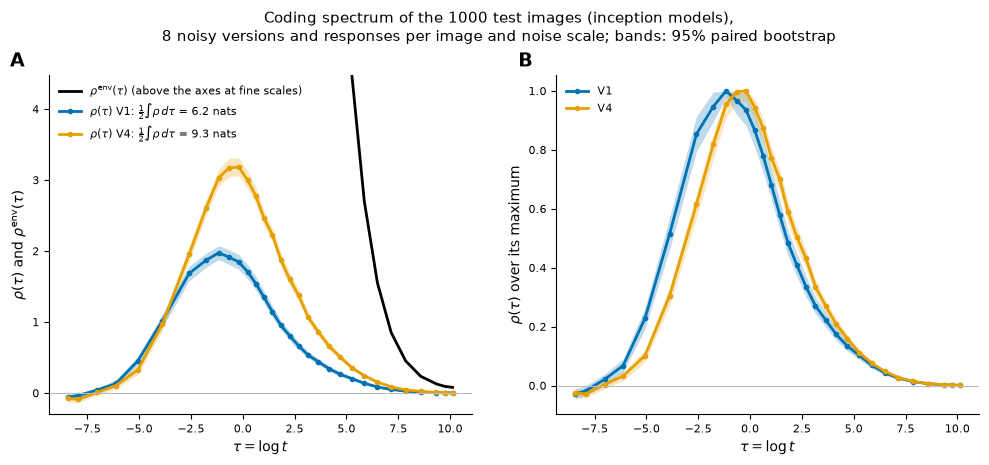

In [6]:
%%time

# 1. the paired bootstrap: the same resamples of the 200 images for V1 and V4
curves = {area: (s.env - s.coded).double().numpy() for area, s in spectra.items()}
bootstrap = compute_bootstrap(curves, PARAMS["n_bootstrap"], PARAMS["bootstrap_seed"])

# 2. the figure, with the 95% band of each curve, also saved
figure_dir = Path(PARAMS["figure_dir"])
figure_dir.mkdir(parents=True, exist_ok=True)
fig, plotted = plot_coding_spectrum(spectra, bootstrap, PARAMS)
fig.savefig(
    figure_dir / "coding_spectrum.png", dpi=PARAMS["file_dpi"], bbox_inches="tight"
)

# 3. for each area: ½ ∫ ρ dτ in nats (and bits), with its standard error
for area, spectrum in spectra.items():
    mean, sem = compute_information(spectrum.env - spectrum.coded, spectrum.log_tau)
    bits = mean / torch.log(torch.tensor(2.0))
    print(f"{area}: ½∫ρ dτ = {mean:.2f} ± {sem:.2f} nats ({bits:.1f} bits)")

# 4. the paired comparison of the curves over their maxima: the noise scales where
# V4 - V1 is above or below 0 in 95% of the resamples
low, high = compute_band(bootstrap["V4"]["normalized"] - bootstrap["V1"]["normalized"])
log_t = plotted["log_t"]
print("V4 above V1 (over their maxima) at tau =", log_t[low > 0].round(1))
print("V4 below V1 (over their maxima) at tau =", log_t[high < 0].round(1))

## 6. Conclusion

* **The coding spectrum is a bump.** For both areas, $\rho(\tau)$ rises from about zero at the finest levels, peaks at $\log t \approx -1.2$ (2.3 for V1, 3.1 for V4) and falls to about 0.002 at $\log t = 10$, far below the envelope spectrum. The grid of noise levels covers the whole bump.
* **V4 is shifted toward coarse scales, beyond the variation across images.** Over their maxima (B), the two curves peak at the same level, $\log t \approx -1.2$, but V4's is lower below it (0.65 against 0.82 at $\log t = -2.6$) and higher above it (0.64 against 0.43 at $\log t = 1.4$). In the paired bootstrap, V4 − V1 stays below zero from $\log t = -3.9$ to $-1.8$ and above zero from $-0.6$ to 4.7 in 95% of the resamples. In absolute terms (A), the two curves are the same up to $\log t \approx -2.6$; above, V4's is higher, about twice V1's from $\log t \approx 0.6$ to 3.2.
* **The mutual information.** $\tfrac12 \int \rho\, d\tau$ = 6.16 ± 0.18 nats (8.9 bits) for V1 and 9.11 ± 0.23 nats (13.1 bits) for V4: the 50 neurons of V4 carry about 1.5 times more information about the image than the 50 of V1.
* **Caveat: the fine end.** At the finest levels ($\log t \le -6$) the measured $\rho$ is within about 0.15 of zero, and slightly negative at the 2–3 finest levels: there, the errors with and without the responses (about 2600) differ by less than the precision of the networks, so the integrals may miss information carried at the finest scales. The bootstrap bands do not include this error.

**Next steps**: resolve the fine end, for example with a denoiser that is more precise at small noise.